
# **AyurAI — Component 1**
## Comparative Evaluation of Deep Learning Models for Image-Based Anaemia Screening

**Research Project:** AyurAI - *Privacy-Preserving Ayurvedic Risk-Screening and Decision Support for Anaemia*

**Research Component:** Reliability-Aware Multimodal AI Anaemia Screening

**Research Group:** J26-SE-320

**Institution:** Sri Lanka Institute of Information Technology (SLIIT)

---

### 1. Introduction

Anaemia is a significant healthcare concern, particularly in settings where immediate laboratory testing may not be available. Previous research has explored non-invasive anaemia screening using photographs of anatomical regions such as the conjunctiva and fingernail beds.

However, the performance of image-based screening can be affected by image quality, lighting conditions, anatomical differences and the selection of the machine-learning architecture.

Component 1 of AyurAI proposes a multimodal screening system that combines wearable photoplethysmography (PPG), webcam images and structured questionnaire information.

This notebook focuses specifically on the image-processing branch of Component 1.

Three pretrained convolutional neural network architectures will be investigated:

1. MobileNetV2
2. EfficientNet-B0
3. ResNet-50

The models will be evaluated under comparable experimental conditions to identify an appropriate image-feature extractor for the proposed reliability-aware multimodal screening system.

The final selected image model will provide features and prediction outputs to the multimodal fusion stage.

**Clinical scope:** This is research into preliminary anaemia-risk screening. Its predictions are not intended to replace laboratory haemoglobin measurements or clinical diagnosis.



### 2. Research Objectives

**Main Objective**

To evaluate and compare three convolutional neural network architectures for extracting anaemia-related visual information from anatomical images and identify a suitable candidate for integration into the AyurAI multimodal screening framework.

**Specific Objectives**

1. To investigate MobileNetV2, EfficientNet-B0 and ResNet-50 using transfer learning.

2. To preprocess anatomical images using consistent resizing, normalization and image-quality assessment methods.

3. To train and evaluate the candidate models using appropriately labelled public research datasets.

4. To compare the models using accuracy, sensitivity, specificity, F1-score, model size and inference time.

5. To investigate the effect of image degradation, including blur and poor illumination, on prediction performance.

6. To select an image-processing architecture based on experimental evidence rather than model complexity alone.

7. To prepare the selected architecture for integration with the PPG and questionnaire branches of AyurAI.

### Research Question

Which of the selected CNN architectures offers the most suitable balance of predictive performance, computational efficiency and robustness for image-based anaemia screening?

### Research Hypothesis

Different CNN architectures will exhibit different trade-offs between predictive performance, computational complexity and robustness to image degradation.

The experimental results will determine whether any candidate provides a meaningful advantage for the intended application.



### 3. Candidate Model Selection and Justification

Three established CNN architectures were selected for comparison because they represent different approaches to computational efficiency and image-feature extraction.

#### **3.1 MobileNetV2**

MobileNetV2 is designed for computational efficiency and uses inverted residual blocks and depthwise separable convolutions.

It was selected as a lightweight baseline because the proposed AyurAI system is intended for use in resource-constrained clinical settings.

Its relatively small model size may support faster inference, although predictive performance must be verified experimentally.

#### **3.2 EfficientNet-B0**

EfficientNet-B0 uses compound scaling to balance network depth, width and input resolution.

It was selected to investigate whether an architecture designed around computational efficiency can provide an appropriate balance between classification performance and model complexity.

Its performance will be compared with MobileNetV2 and ResNet-50 using the same evaluation procedure.

#### **3.3 ResNet-50**

ResNet-50 is a deeper residual convolutional neural network that uses skip connections to support the training of deep architectures.

It was selected as a higher-capacity candidate for extracting detailed image representations.

Pretrained ImageNet weights will be considered for transfer learning to reduce the need for training the entire model from randomly initialized weights.

However, its greater computational complexity and potential for overfitting on small medical-image datasets must be considered.

### **3.4 Comparison Strategy**

All three models will be evaluated using consistent data partitions and equivalent experimental procedures.

The comparison will focus on:

- Classification performance
- Sensitivity and specificity
- F1-score and AUROC, where applicable
- Model size and inference time
- Robustness to image-quality degradation
- Suitability for integration into AyurAI

**Model selection status:** No final model has been selected. The decision will be based on the experimental results.



### 4. Experimental Environment

The experiments will be developed using Python and PyTorch in Google Colab.

**Development Tools**

- Python — primary programming language.
- PyTorch — neural network development and training.
- Torchvision — pretrained CNN architectures and image transformations.
- NumPy — numerical operations.
- Pandas — dataset handling and results analysis.
- Matplotlib — performance graphs and visualisation.
- Scikit-learn — evaluation metrics and model comparison.

GPU acceleration will be used when available to reduce training time.

The experimental environment, library versions and hardware availability will be recorded to support reproducibility.

Only appropriately licensed public research datasets will be considered for cloud-based experimentation. Private hospital records, participant images and identifiable clinical information will not be uploaded to Google Colab.

If the project requires all data processing to remain on-premises, the experiment will instead be executed on approved local infrastructure.


In [2]:

# AyurAI Component 1
# Experiment 01: Verify the Deep Learning Environment

import sys
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib
import sklearn

print("=" * 50)
print("AYURAI COMPONENT 1 - ENVIRONMENT CHECK")
print("=" * 50)

print("Python Version:", sys.version.split()[0])
print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("Matplotlib Version:", matplotlib.__version__)
print("Scikit-learn Version:", sklearn.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nSelected Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. CPU mode selected.")

print("\nEnvironment verification completed.")


AYURAI COMPONENT 1 - ENVIRONMENT CHECK
Python Version: 3.13.7
PyTorch Version: 2.11.0+cu130
Torchvision Version: 0.26.0+cu130
NumPy Version: 2.5.3
Pandas Version: 3.0.6
Matplotlib Version: 3.11.2
Scikit-learn Version: 1.9.1

Selected Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU

Environment verification completed.



### 5. CNN Architecture Verification

Before training, the three candidate architectures must be initialized and examined.

The purpose of this stage is to confirm that the required implementations are available and compare their approximate parameter counts.

The parameter count provides an initial indication of model complexity, although it does not directly establish predictive performance or inference speed.

At this stage, models are created without pretrained weights. This is only an architecture verification step; no training, fine-tuning or clinical evaluation is performed.


In [3]:

# Experiment 02: Compare CNN Architecture Sizes

from torchvision.models import (
    mobilenet_v2,
    efficientnet_b0,
    resnet50
)

model_builders = {
    "MobileNetV2": mobilenet_v2,
    "EfficientNet-B0": efficientnet_b0,
    "ResNet-50": resnet50
}

comparison_results = []

for model_name, build_model in model_builders.items():

    # No pretrained weights are downloaded yet
    model = build_model(weights=None)

    total_parameters = sum(
        p.numel() for p in model.parameters()
    )

    trainable_parameters = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    comparison_results.append({
        "Model": model_name,
        "Parameters": total_parameters,
        "Trainable Parameters": trainable_parameters,
        "Parameters (Millions)": round(
            total_parameters / 1_000_000, 2
        )
    })

    del model

results_df = pd.DataFrame(comparison_results)

print("AYURAI - CNN ARCHITECTURE COMPARISON")
display(results_df)

print("\nAll three models initialized successfully.")


AYURAI - CNN ARCHITECTURE COMPARISON


,Model,Parameters,Trainable Parameters,Parameters (Millions)
0,MobileNetV2,3504872,3504872,3.50
1,EfficientNet-B0,5288548,5288548,5.29
2,ResNet-50,25557032,25557032,25.56



All three models initialized successfully.



### 6. Initial Experiment Observations

The initial environment verification confirms whether PyTorch and the selected CNN architectures can be executed using the available computing resources.

The architecture comparison records the parameter counts for MobileNetV2, EfficientNet-B0 and ResNet-50.

These results establish a baseline for comparing computational complexity.

However, parameter count alone is insufficient to determine the most suitable model for anaemia-related image classification.

The next experiment will inspect the available dataset, verify its labels, identify participant-level grouping information and establish appropriate training, validation and testing partitions.

**Current experiment status:** Architecture verification only. No model has been trained or evaluated.

**Next experiment:** Dataset exploration and preparation.



### 7.5 Preliminary Dataset Inspection

The CP-AnemiC dataset metadata workbook was inspected before model training.

The workbook contains 251 image records with two provided classification labels:

- Anaemic: 110 images
- Non-anaemic: 141 images

Numerical haemoglobin measurements are available for all 251 records, ranging from 4.2 to 15.0 g/dL.

The initial image-model experiment will therefore investigate binary anaemia classification using MobileNetV2, EfficientNet-B0 and ResNet-50.

Before training, image-file matching, duplicate detection, participant grouping and label consistency must be verified.

The binary class labels will be treated as the dataset's provided labels. The experimental results will not be interpreted as proof of performance for three-class risk screening or for a different patient population.


In [4]:

# Experiment 03: Verify local GPU

import sys
import torch

print("Python Environment:", sys.executable)
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(100, 100, device="cuda")
    result = x @ x

    print("GPU Calculation:", result.shape)
    print("Local GPU verification successful!")
else:
    print("GPU not detected!")


Python Environment: d:\Nim's Stuff\Academics\Sliit\4th Year\Reasearch\AyurAI\AyurAI-RP\component1\.venv\Scripts\python.exe
PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
GPU Calculation: torch.Size([100, 100])
Local GPU verification successful!



### Experiment 04 — Local Dataset Verification

This experiment verifies the CP-AnemiC conjunctiva dataset, image counts and laboratory Hb metadata before model training.


In [5]:

# Experiment 04: Load the CP-AnemiC dataset locally

from pathlib import Path
import pandas as pd

DATASET_DIR = Path(
    r"D:\Nim's Stuff\Academics\Sliit\4th Year\Reasearch\AyurAI\datasets\Cp-Anameic Dataset V2"
)

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset not found: {DATASET_DIR}")

print("Dataset found successfully!")

for category in ["Anaemic", "Non-Anaemic"]:
    folder = DATASET_DIR / category

    images = [
        p for p in folder.rglob("*")
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]

    print(f"{category}: {len(images)} images")

excel_files = list(DATASET_DIR.glob("*.xlsx"))

if not excel_files:
    raise FileNotFoundError("Metadata Excel file not found.")

df = pd.read_excel(excel_files[0], sheet_name=0)

print("\nMetadata records:", len(df))
print("Columns:", df.columns.tolist())

display(df.head())

print("\nLocal dataset verification completed!")


Dataset found successfully!
Anaemic: 110 images
Non-Anaemic: 141 images

Metadata records: 251
Columns: ['Image_ID', 'File_Name', 'Folder_Label', 'Hb_g_dl']


,Image_ID,File_Name,Folder_Label,Hb_g_dl
0,Image_004,Image_004.png,Non-anemic,12.5
1,Image_008,Image_008.png,Non-anemic,12.5
2,Image_012,Image_012.png,Non-anemic,12.5
3,Image_014,Image_014.png,Non-anemic,12.4
4,Image_020,Image_020.png,Non-anemic,11.3



Local dataset verification completed!



### Experiment 05 — Image and Label Verification

Match each conjunctiva image to its anaemia label and laboratory Hb value. Check for missing files and duplicates before model training.


In [6]:

# Experiment 05: Verify image-label matching

import hashlib

image_df = df.copy()

# Convert labels into numeric classes
image_df["label"] = (
    image_df["Folder_Label"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "non-anaemic": 0,
        "non-anemic": 0,
        "anaemic": 1,
        "anemic": 1
    })
)

print("Original labels:", image_df["Folder_Label"].unique())
print("Unrecognized labels:", image_df["label"].isna().sum())

# Match each record to its image file
def get_image_path(row):
    folder = "Anaemic" if row["label"] == 1 else "Non-Anaemic"
    return DATASET_DIR / folder / str(row["File_Name"])

if image_df["label"].isna().any():
    raise ValueError("Unknown classification labels found.")

image_df["image_path"] = image_df.apply(get_image_path, axis=1)

# Check missing image files
missing = image_df[
    ~image_df["image_path"].apply(lambda p: p.is_file())
]

# Check duplicate filenames
duplicate_names = image_df["File_Name"].duplicated().sum()

# Check exact duplicate image contents
hashes = [
    hashlib.sha256(p.read_bytes()).hexdigest()
    for p in image_df.loc[
        image_df["image_path"].apply(lambda p: p.is_file()),
        "image_path"
    ]
]

duplicate_contents = len(hashes) - len(set(hashes))

print("AYURAI - IMAGE DATASET VERIFICATION")
print("-----------------------------------")
print("Total records:", len(image_df))
print("Anaemic:", (image_df["label"] == 1).sum())
print("Non-anaemic:", (image_df["label"] == 0).sum())
print("Missing images:", len(missing))
print("Duplicate filenames:", duplicate_names)
print("Exact duplicate image contents:", duplicate_contents)
print("Hb values available:", image_df["Hb_g_dl"].notna().sum())

if len(missing) == 0:
    print("\nAll image files matched successfully!")

display(image_df[
    ["File_Name", "Folder_Label", "Hb_g_dl", "label"]
].head())


Original labels: <StringArray>
['Non-anemic', 'Anemic']
Length: 2, dtype: str
Unrecognized labels: 0
AYURAI - IMAGE DATASET VERIFICATION
-----------------------------------
Total records: 251
Anaemic: 110
Non-anaemic: 141
Missing images: 0
Duplicate filenames: 0
Exact duplicate image contents: 0
Hb values available: 251

All image files matched successfully!


,File_Name,Folder_Label,Hb_g_dl,label
0,Image_004.png,Non-anemic,12.5,0
1,Image_008.png,Non-anemic,12.5,0
2,Image_012.png,Non-anemic,12.5,0
3,Image_014.png,Non-anemic,12.4,0
4,Image_020.png,Non-anemic,11.3,0



### Experiment 06 — Training, Validation and Test Split

The dataset is divided into 70% training, 15% validation and 15% testing.

Stratified splitting preserves the approximate proportion of anaemic and non-anaemic images.

The same split will be used for MobileNetV2, EfficientNet-B0 and ResNet-50 to ensure a fair comparison.

This is a preliminary image-level evaluation. Patient-level independence has not yet been verified.


In [7]:

# Experiment 06: Create train, validation and test datasets

from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# First split: 70% training and 30% temporary
train_df, temp_df = train_test_split(
    image_df,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=image_df["label"]
)

# Divide temporary data into validation and testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temp_df["label"]
)

# Reset row indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("AYURAI - DATASET SPLIT RESULTS")
print("-" * 40)

for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}: {len(data)} images")
    print("Anaemic:", (data["label"] == 1).sum())
    print("Non-anaemic:", (data["label"] == 0).sum())

# Ensure no file appears in multiple splits
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

assert len(train_df) + len(val_df) + len(test_df) == 251

print("\nNo image-file overlap between splits.")
print("Dataset splitting completed successfully!")


AYURAI - DATASET SPLIT RESULTS
----------------------------------------

Training: 175 images
Anaemic: 77
Non-anaemic: 98

Validation: 38 images
Anaemic: 17
Non-anaemic: 21

Testing: 38 images
Anaemic: 16
Non-anaemic: 22

No image-file overlap between splits.
Dataset splitting completed successfully!



### Experiment 07 — Image Preprocessing

Convert conjunctiva images into normalized 224 × 224 RGB tensors and prepare PyTorch DataLoaders for training, validation and testing.

The same preprocessing will be used for all three CNN architectures to ensure a fair comparison.


In [8]:

# Experiment 07: Image preprocessing and DataLoaders

import torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMAGE_SIZE = 224
BATCH_SIZE = 16

# Normalization used by ImageNet-pretrained CNNs
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ConjunctivaDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        with Image.open(row["image_path"]) as original:
            # Handle transparent PNG images consistently
            rgba = original.convert("RGBA")

            background = Image.new(
                "RGBA", rgba.size, (255, 255, 255, 255)
            )
            background.alpha_composite(rgba)

            image = background.convert("RGB")

        # Resize without stretching anatomical structures
        image = ImageOps.pad(
            image,
            (IMAGE_SIZE, IMAGE_SIZE),
            method=Image.Resampling.BILINEAR,
            color=(255, 255, 255)
        )

        image = self.transform(image)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return image, label


# Create separate dataset objects
train_dataset = ConjunctivaDataset(
    train_df, image_transform
)

val_dataset = ConjunctivaDataset(
    val_df, image_transform
)

test_dataset = ConjunctivaDataset(
    test_df, image_transform
)


# Prepare batches for model training
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


# Verify the first batch
images, labels = next(iter(train_loader))

print("AYURAI - IMAGE PREPROCESSING")
print("-" * 40)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image data type:", images.dtype)

print("\nImage preprocessing completed successfully!")


AYURAI - IMAGE PREPROCESSING
----------------------------------------
Training images: 175
Validation images: 38
Testing images: 38

Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Image data type: torch.float32

Image preprocessing completed successfully!



### Experiment 08 — MobileNetV2 Transfer Learning

MobileNetV2 is a lightweight CNN designed for efficient image classification.

We use pretrained ImageNet weights, freeze the feature-extraction layers and train a new classifier for two classes: Anaemic and Non-anaemic.

Training performance will be monitored using validation accuracy and F1-score.


In [9]:

# Experiment 08: Train MobileNetV2

import torch
import torch.nn as nn
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from sklearn.metrics import accuracy_score, f1_score, recall_score
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)

# Loading ImageNet pretrained MobileNetV2
model = mobilenet_v2(
    weights=MobileNet_V2_Weights.DEFAULT
)

# Freeze pretrained feature extraction layers
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Replace original classifier with 2 outputs
model.classifier[-1] = nn.Linear(
    model.classifier[-1].in_features,
    2
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

EPOCHS = 5

history = []

for epoch in range(EPOCHS):

    model.train()

    # Keep frozen feature extractor in evaluation mode
    model.features.eval()

    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(images)

        loss = criterion(predictions, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_dataset)

    # Validation
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)

            outputs = model(images)
            predicted = outputs.argmax(dim=1)

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(predicted.cpu().numpy().tolist())

    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    sensitivity = recall_score(y_true, y_pred, zero_division=0)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_accuracy": accuracy,
        "val_f1": f1,
        "val_sensitivity": sensitivity
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Val Acc: {accuracy:.4f} | "
        f"Val F1: {f1:.4f} | "
        f"Sensitivity: {sensitivity:.4f}"
    )

print("\nMobileNetV2 initial training completed!")

# Save the trained model outside the Git repository
OUTPUT_DIR = DATASET_DIR.parent / "trained_model_artifacts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    model.state_dict(),
    OUTPUT_DIR / "mobilenetv2_initial.pth"
)

print("Model saved to:", OUTPUT_DIR)


Epoch 1/5 | Loss: 0.7109 | Val Acc: 0.5789 | Val F1: 0.1111 | Sensitivity: 0.0588
Epoch 2/5 | Loss: 0.6635 | Val Acc: 0.6579 | Val F1: 0.4348 | Sensitivity: 0.2941
Epoch 3/5 | Loss: 0.6410 | Val Acc: 0.6579 | Val F1: 0.4800 | Sensitivity: 0.3529
Epoch 4/5 | Loss: 0.6113 | Val Acc: 0.6316 | Val F1: 0.4167 | Sensitivity: 0.2941
Epoch 5/5 | Loss: 0.5932 | Val Acc: 0.6316 | Val F1: 0.4167 | Sensitivity: 0.2941

MobileNetV2 initial training completed!
Model saved to: D:\Nim's Stuff\Academics\Sliit\4th Year\Reasearch\AyurAI\datasets\trained_model_artifacts



### Experiment 09 — EfficientNet-B0 and ResNet-50 Training

EfficientNet-B0 and ResNet-50 are trained using ImageNet transfer learning.

Their pretrained feature extractors are frozen, and new binary classification layers are trained using the same dataset and training settings as MobileNetV2.

The results will be compared to identify a suitable model for the conjunctiva image branch.


In [10]:

# Experiment 09: Train EfficientNet-B0 and ResNet-50

import torch
import torch.nn as nn
import pandas as pd

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights,
    resnet50,
    ResNet50_Weights
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def create_model(model_name):

    if model_name == "EfficientNet-B0":

        model = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        for param in model.features.parameters():
            param.requires_grad = False

        model.classifier[-1] = nn.Linear(
            model.classifier[-1].in_features, 2
        )

        backbone = model.features
        classifier = model.classifier

    elif model_name == "ResNet-50":

        model = resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        for param in model.parameters():
            param.requires_grad = False

        model.fc = nn.Linear(
            model.fc.in_features, 2
        )

        backbone = None
        classifier = model.fc

    else:
        raise ValueError("Unknown model")

    return model.to(device), backbone, classifier


def train_candidate(model_name, epochs=5):

    torch.manual_seed(42)

    model, backbone, classifier = create_model(model_name)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        classifier.parameters(),
        lr=0.001
    )

    history = []

    print(f"\nTraining {model_name}")

    for epoch in range(epochs):

        model.train()

        # Keep pretrained BatchNorm statistics frozen
        if backbone is not None:
            backbone.eval()
        else:
            for module in model.modules():
                if isinstance(module, nn.modules.batchnorm._BatchNorm):
                    module.eval()

        total_loss = 0.0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)

        train_loss = total_loss / len(train_dataset)

        # Evaluate using validation data only
        model.eval()

        y_true = []
        y_pred = []

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)

                outputs = model(images)

                predicted = outputs.argmax(dim=1)

                y_true.extend(labels.tolist())
                y_pred.extend(predicted.cpu().tolist())

        accuracy = accuracy_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        sensitivity = recall_score(
            y_true, y_pred, zero_division=0
        )

        history.append({
            "Model": model_name,
            "Epoch": epoch + 1,
            "Train_Loss": train_loss,
            "Val_Accuracy": accuracy,
            "Val_F1": f1,
            "Val_Sensitivity": sensitivity
        })

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {train_loss:.4f} | "
            f"Accuracy: {accuracy:.4f} | "
            f"F1: {f1:.4f} | "
            f"Sensitivity: {sensitivity:.4f}"
        )

    # Save final-epoch weights outside Git
    filename = model_name.lower().replace("-", "_") + ".pth"

    torch.save(
        model.state_dict(),
        OUTPUT_DIR / filename
    )

    print(f"{model_name} training completed!")
    print("Saved:", OUTPUT_DIR / filename)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return pd.DataFrame(history)


# Train the remaining candidates
efficientnet_history = train_candidate("EfficientNet-B0")
resnet_history = train_candidate("ResNet-50")

# Combine results from both experiments
candidate_history = pd.concat(
    [efficientnet_history, resnet_history],
    ignore_index=True
)

candidate_history.to_csv(
    OUTPUT_DIR / "candidate_training_history.csv",
    index=False
)

print("\nBoth model-training experiments completed!")



Training EfficientNet-B0
Epoch 1/5 | Loss: 0.6661 | Accuracy: 0.6579 | F1: 0.5185 | Sensitivity: 0.4118
Epoch 2/5 | Loss: 0.5886 | Accuracy: 0.6842 | F1: 0.5385 | Sensitivity: 0.4118
Epoch 3/5 | Loss: 0.5545 | Accuracy: 0.7105 | F1: 0.6207 | Sensitivity: 0.5294
Epoch 4/5 | Loss: 0.5375 | Accuracy: 0.7105 | F1: 0.6207 | Sensitivity: 0.5294
Epoch 5/5 | Loss: 0.5173 | Accuracy: 0.6842 | F1: 0.5714 | Sensitivity: 0.4706
EfficientNet-B0 training completed!
Saved: D:\Nim's Stuff\Academics\Sliit\4th Year\Reasearch\AyurAI\datasets\trained_model_artifacts\efficientnet_b0.pth
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\Ehara Perera/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100.0%



Training ResNet-50
Epoch 1/5 | Loss: 0.6985 | Accuracy: 0.6053 | F1: 0.5161 | Sensitivity: 0.4706
Epoch 2/5 | Loss: 0.6306 | Accuracy: 0.5789 | F1: 0.3333 | Sensitivity: 0.2353
Epoch 3/5 | Loss: 0.5852 | Accuracy: 0.6316 | F1: 0.5625 | Sensitivity: 0.5294
Epoch 4/5 | Loss: 0.5508 | Accuracy: 0.6053 | F1: 0.4000 | Sensitivity: 0.2941
Epoch 5/5 | Loss: 0.5320 | Accuracy: 0.6053 | F1: 0.4000 | Sensitivity: 0.2941
ResNet-50 training completed!
Saved: D:\Nim's Stuff\Academics\Sliit\4th Year\Reasearch\AyurAI\datasets\trained_model_artifacts\resnet_50.pth

Both model-training experiments completed!



### Experiment 10 — CNN Model Comparison

Compare MobileNetV2, EfficientNet-B0 and ResNet-50 using validation accuracy, F1-score and sensitivity.

The best validation epoch is recorded for each architecture. The results are preliminary and will guide further evaluation.


AYURAI - CNN MODEL COMPARISON


,Model,Epoch,Val_Accuracy,Val_F1,Val_Sensitivity
7,EfficientNet-B0,3,0.710526,0.62069,0.529412
12,ResNet-50,3,0.631579,0.56250,0.529412
2,MobileNetV2,3,0.657895,0.48000,0.352941


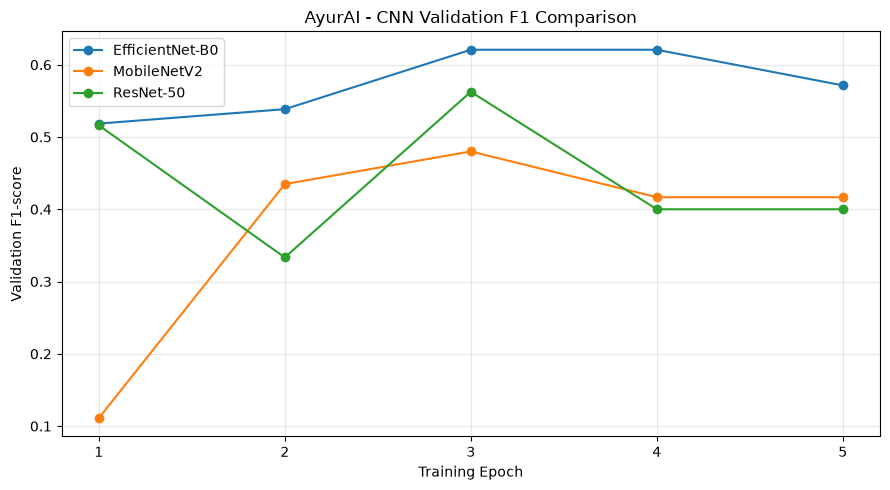


Comparison report and graph saved!


In [11]:

# Experiment 10: Compare all three trained CNN models

import pandas as pd
import matplotlib.pyplot as plt

# MobileNetV2 history from Experiment 08
mobilenet_df = pd.DataFrame(history).rename(columns={
    "epoch": "Epoch",
    "train_loss": "Train_Loss",
    "val_accuracy": "Val_Accuracy",
    "val_f1": "Val_F1",
    "val_sensitivity": "Val_Sensitivity"
})

mobilenet_df["Model"] = "MobileNetV2"

# EfficientNet-B0 and ResNet-50 from Experiment 09
other_models_df = candidate_history.copy()

# Combine results
all_results = pd.concat(
    [mobilenet_df, other_models_df],
    ignore_index=True
)

# Select the highest-F1 validation epoch per model
best_results = (
    all_results
    .sort_values(
        ["Val_F1", "Val_Sensitivity"],
        ascending=False
    )
    .drop_duplicates(subset=["Model"])
    .sort_values("Val_F1", ascending=False)
)

print("AYURAI - CNN MODEL COMPARISON")
display(best_results[[
    "Model",
    "Epoch",
    "Val_Accuracy",
    "Val_F1",
    "Val_Sensitivity"
]])

# Plot validation F1 across epochs
plt.figure(figsize=(9, 5))

for model_name, group in all_results.groupby("Model"):
    plt.plot(
        group["Epoch"],
        group["Val_F1"],
        marker="o",
        label=model_name
    )

plt.title("AyurAI - CNN Validation F1 Comparison")
plt.xlabel("Training Epoch")
plt.ylabel("Validation F1-score")
plt.xticks(range(1, 6))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save experimental evidence
best_results.to_csv(
    OUTPUT_DIR / "image_model_comparison.csv",
    index=False
)

plt.savefig(
    OUTPUT_DIR / "image_model_f1_comparison.png",
    dpi=200
)

plt.show()

print("\nComparison report and graph saved!")


In [13]:

# Experiment 11: Save model comparison evidence to Git repository

from pathlib import Path
import shutil

# Find AyurAI-RP next to the datasets folder
REPO_ROOT = DATASET_DIR.parent.parent / "AyurAI-RP"

if not (REPO_ROOT / "component1").exists():
    raise FileNotFoundError(f"Repository not found: {REPO_ROOT}")

REPORT_DIR = REPO_ROOT / "component1" / "evaluation" / "images"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Save complete training history
all_results.to_csv(
    REPORT_DIR / "image_model_training_history.csv",
    index=False
)

# Save best validation results
best_results.to_csv(
    REPORT_DIR / "image_model_comparison.csv",
    index=False
)

# Copy previously generated F1 graph
source_graph = OUTPUT_DIR / "image_model_f1_comparison.png"

if not source_graph.exists():
    raise FileNotFoundError(f"Graph not found: {source_graph}")

shutil.copy2(
    source_graph,
    REPORT_DIR / "image_model_f1_comparison.png"
)

print("AYURAI - EXPERIMENTAL EVIDENCE SAVED")
print("-" * 45)

for file in sorted(REPORT_DIR.iterdir()):
    print("Saved:", file.name)

print("\nEvidence folder:", REPORT_DIR)


AYURAI - EXPERIMENTAL EVIDENCE SAVED
---------------------------------------------
Saved: image_model_comparison.csv
Saved: image_model_f1_comparison.png
Saved: image_model_training_history.csv

Evidence folder: D:\Nim's Stuff\Academics\Sliit\4th Year\Reasearch\AyurAI\AyurAI-RP\component1\evaluation\images



### Experiment 12 — Best Model Checkpoint

EfficientNet-B0 achieved the highest validation F1-score among the three CNN candidates.

This experiment retrains EfficientNet-B0 and saves the checkpoint with the best validation F1-score, using sensitivity as a tie-breaker.

The selected checkpoint will be evaluated on the held-out test dataset in the next experiment.


In [14]:

# Experiment 12: Retrain and save best EfficientNet-B0 checkpoint

import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import accuracy_score, f1_score, recall_score

torch.manual_seed(42)

best_model = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

# Freeze pretrained feature extractor
for param in best_model.features.parameters():
    param.requires_grad = False

# Binary classification: 0 = Non-anaemic, 1 = Anaemic
best_model.classifier[-1] = nn.Linear(
    best_model.classifier[-1].in_features, 2
)

best_model = best_model.to(device)

optimizer = torch.optim.Adam(
    best_model.classifier.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss()

best_f1 = -1.0
best_sensitivity = -1.0
best_epoch = 0

checkpoint_path = OUTPUT_DIR / "efficientnet_b0_best.pth"

for epoch in range(5):

    best_model.train()
    best_model.features.eval()

    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = best_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    # Validation
    best_model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)

            outputs = best_model(images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.tolist())
            y_pred.extend(predictions.cpu().tolist())

    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    sensitivity = recall_score(
        y_true, y_pred, zero_division=0
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Accuracy: {accuracy:.4f} | "
        f"F1: {f1:.4f} | "
        f"Sensitivity: {sensitivity:.4f}"
    )

    # Save only when validation performance improves
    if (
        f1 > best_f1 or
        (f1 == best_f1 and sensitivity > best_sensitivity)
    ):
        best_f1 = f1
        best_sensitivity = sensitivity
        best_epoch = epoch + 1

        torch.save(
            best_model.state_dict(),
            checkpoint_path
        )

        print("  -> Best checkpoint saved!")

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print("Best validation F1:", round(best_f1, 4))
print("Best validation sensitivity:", round(best_sensitivity, 4))
print("Checkpoint:", checkpoint_path)


Epoch 1/5 | Accuracy: 0.6579 | F1: 0.5185 | Sensitivity: 0.4118
  -> Best checkpoint saved!
Epoch 2/5 | Accuracy: 0.6842 | F1: 0.5385 | Sensitivity: 0.4118
  -> Best checkpoint saved!
Epoch 3/5 | Accuracy: 0.7105 | F1: 0.6207 | Sensitivity: 0.5294
  -> Best checkpoint saved!
Epoch 4/5 | Accuracy: 0.7105 | F1: 0.6207 | Sensitivity: 0.5294
Epoch 5/5 | Accuracy: 0.6842 | F1: 0.5714 | Sensitivity: 0.4706

Training completed!
Best epoch: 3
Best validation F1: 0.6207
Best validation sensitivity: 0.5294
Checkpoint: D:\Nim's Stuff\Academics\Sliit\4th Year\Reasearch\AyurAI\datasets\trained_model_artifacts\efficientnet_b0_best.pth



### Experiment 13 — Selected Model Testing

Evaluate the best EfficientNet-B0 checkpoint on the held-out test dataset.

Calculate accuracy, sensitivity, specificity, F1-score and AUROC. Generate a confusion matrix to examine correct predictions and classification errors.

These are preliminary image-level results, not independent clinical validation.


AYURAI - EFFICIENTNET-B0 TEST RESULTS
---------------------------------------------
Accuracy:    0.5000
Sensitivity: 0.3125
Specificity: 0.6364
F1-score:    0.3448
AUROC:       0.4744

Classification Report:
              precision    recall  f1-score   support

 Non-anaemic       0.56      0.64      0.60        22
     Anaemic       0.38      0.31      0.34        16

    accuracy                           0.50        38
   macro avg       0.47      0.47      0.47        38
weighted avg       0.49      0.50      0.49        38



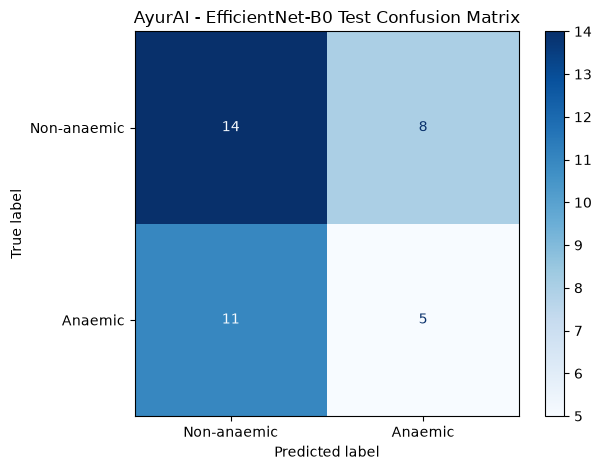


Test evaluation completed!
Report saved to: D:\Nim's Stuff\Academics\Sliit\4th Year\Reasearch\AyurAI\AyurAI-RP\component1\evaluation\images


In [15]:

# Experiment 13: Evaluate best EfficientNet-B0

import torch
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Load the best checkpoint (not the final epoch)
best_model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

best_model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = best_model(images)
        probabilities = torch.softmax(outputs, dim=1)

        predictions = probabilities.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())
        y_prob.extend(probabilities[:, 1].cpu().tolist())

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
sensitivity = recall_score(y_true, y_pred, pos_label=1)
specificity = recall_score(y_true, y_pred, pos_label=0)
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("AYURAI - EFFICIENTNET-B0 TEST RESULTS")
print("-" * 45)

print(f"Accuracy:    {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1-score:    {f1:.4f}")
print(f"AUROC:       {auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true, y_pred,
        target_names=["Non-anaemic", "Anaemic"],
        zero_division=0
    )
)

# Save evaluation results in Git repository
report_dir = (
    DATASET_DIR.parent.parent
    / "AyurAI-RP"
    / "component1"
    / "evaluation"
    / "images"
)

report_dir.mkdir(parents=True, exist_ok=True)

metrics = pd.DataFrame([{
    "Model": "EfficientNet-B0",
    "Test_Accuracy": accuracy,
    "Test_Sensitivity": sensitivity,
    "Test_Specificity": specificity,
    "Test_F1": f1,
    "Test_AUROC": auc
}])

metrics.to_csv(
    report_dir / "efficientnet_test_metrics.csv",
    index=False
)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-anaemic", "Anaemic"]
).plot(cmap="Blues", values_format="d")

plt.title("AyurAI - EfficientNet-B0 Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    report_dir / "efficientnet_test_confusion_matrix.png",
    dpi=200
)

plt.show()

print("\nTest evaluation completed!")
print("Report saved to:", report_dir)
